In [2]:
import pandas as pd
df = pd.read_csv("final_merge.csv")
df

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test,3,46,29.5,U,2,25454.66,2,6
1,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test,3,46,29.5,U,2,25454.66,2,6
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test,3,46,29.5,U,2,25454.66,2,6
3,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test,3,46,29.5,U,2,25454.66,2,6
4,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test,3,46,29.5,U,2,25454.66,2,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317130,9999729,834634258_21862004160,870243567_56915814033_814203,confirm,2017-05-08 16:09:40,Test,10,124,31.0,F,3,107059.74,6,9
317131,9999729,604429154_69247391147,99583652_41711450505_426179,start,2017-04-05 13:40:49,Test,10,124,31.0,F,3,107059.74,6,9
317132,9999729,604429154_69247391147,99583652_41711450505_426179,step_1,2017-04-05 13:41:04,Test,10,124,31.0,F,3,107059.74,6,9
317133,9999832,145538019_54444341400,472154369_16714624241_585315,start,2017-05-16 16:46:03,Test,23,281,49.0,F,2,431887.61,1,4


In [3]:
# date_time to datetime type
df["date_time"] = pd.to_datetime(df["date_time"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   client_id         317135 non-null  int64         
 1   visitor_id        317135 non-null  str           
 2   visit_id          317135 non-null  str           
 3   process_step      317135 non-null  str           
 4   date_time         317135 non-null  datetime64[us]
 5   variation         317135 non-null  str           
 6   clnt_tenure_yr    317135 non-null  int64         
 7   clnt_tenure_mnth  317135 non-null  int64         
 8   clnt_age          317135 non-null  float64       
 9   gendr             317135 non-null  str           
 10  num_accts         317135 non-null  int64         
 11  bal               317135 non-null  float64       
 12  calls_6_mnth      317135 non-null  int64         
 13  logons_6_mnth     317135 non-null  int64         
dtypes: datetime64[u

In [4]:
df = df.sort_values(["client_id", "visit_id", "date_time"])
df.head(40)

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test,3,46,29.5,U,2,25454.66,2,6
1,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test,3,46,29.5,U,2,25454.66,2,6
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test,3,46,29.5,U,2,25454.66,2,6
3,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test,3,46,29.5,U,2,25454.66,2,6
4,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test,3,46,29.5,U,2,25454.66,2,6
5,647,66758770_53988066587,40369564_40101682850_311847,start,2017-04-12 15:41:28,Test,12,151,57.5,M,2,30525.80,0,4
6,647,66758770_53988066587,40369564_40101682850_311847,step_1,2017-04-12 15:41:35,Test,12,151,57.5,M,2,30525.80,0,4
7,647,66758770_53988066587,40369564_40101682850_311847,step_2,2017-04-12 15:41:53,Test,12,151,57.5,M,2,30525.80,0,4
8,647,66758770_53988066587,40369564_40101682850_311847,step_3,2017-04-12 15:45:02,Test,12,151,57.5,M,2,30525.80,0,4
9,647,66758770_53988066587,40369564_40101682850_311847,confirm,2017-04-12 15:47:45,Test,12,151,57.5,M,2,30525.80,0,4


In [5]:

df["next_step"] = df.groupby(["client_id", "visit_id"])["process_step"].shift(-1)
df

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,next_step
0,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test,3,46,29.5,U,2,25454.66,2,6,step_1
1,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test,3,46,29.5,U,2,25454.66,2,6,step_2
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test,3,46,29.5,U,2,25454.66,2,6,step_3
3,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test,3,46,29.5,U,2,25454.66,2,6,confirm
4,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test,3,46,29.5,U,2,25454.66,2,6,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317130,9999729,834634258_21862004160,870243567_56915814033_814203,confirm,2017-05-08 16:09:40,Test,10,124,31.0,F,3,107059.74,6,9,NaN
317131,9999729,604429154_69247391147,99583652_41711450505_426179,start,2017-04-05 13:40:49,Test,10,124,31.0,F,3,107059.74,6,9,step_1
317132,9999729,604429154_69247391147,99583652_41711450505_426179,step_1,2017-04-05 13:41:04,Test,10,124,31.0,F,3,107059.74,6,9,NaN
317133,9999832,145538019_54444341400,472154369_16714624241_585315,start,2017-05-16 16:46:03,Test,23,281,49.0,F,2,431887.61,1,4,step_1


In [6]:
#column that takes the value true if the client goes back to start from a later step
df["back_to_start"] = (df["next_step"] == "start") & (df["process_step"] != "start")

df["back_to_start"].value_counts()

back_to_start
False    301814
True      15321
Name: count, dtype: int64

In [7]:
# Making one row per visit, grouping by
visits = df.groupby(["client_id", "visit_id", "variation"])["back_to_start"].max().reset_index()
visits = visits.rename(columns={"back_to_start": "restarted"})
visits

,client_id,visit_id,variation,restarted
0,555,637149525_38041617439_716659,Test,False
1,647,40369564_40101682850_311847,Test,False
2,934,7076463_57954418406_971348,Test,False
3,1028,557292053_87239438319_391157,Control,False
4,1104,543158812_46395476577_767725,Control,False
...,...,...,...,...
69422,9999626,182723364_27031318473_880901,Test,False
69423,9999729,493310979_9209676464_421146,Test,True
69424,9999729,870243567_56915814033_814203,Test,False
69425,9999729,99583652_41711450505_426179,Test,False


In [8]:
# Number of visits per group
visits["variation"].value_counts()

variation
Test       37190
Control    32237
Name: count, dtype: int64

In [9]:
# checking the mean of true per group and multiplying by 100 to get a percentage
restart_rate = visits.groupby("variation")["restarted"].mean() * 100
restart_rate.round(2)

variation
Control    12.65
Test       22.48
Name: restarted, dtype: float64

In [10]:
# checking the difference between the two groups in percentage points 
difference_rate = restart_rate ['Test'] - restart_rate ['Control']
difference_rate

np.float64(9.825998549679992)

In [11]:
# getting the difference relative comparing difference and control restart rate
difference_relative = difference_rate/ restart_rate["Control"] * 100
difference_relative

np.float64(77.65646365433537)

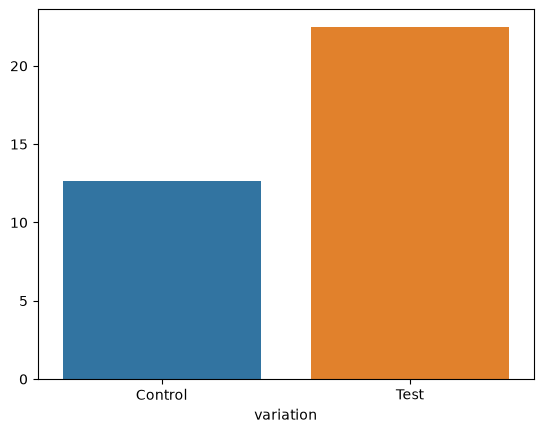

In [12]:
import seaborn as sns
ax = sns.barplot(x=restart_rate.index, y=restart_rate.values, hue=restart_rate.index, order=["Control", "Test"])


FINDING THE STEP THEY RESTART FROM THE MOST

In [13]:
# moves that went back to start
df_restarts = df[df["back_to_start"]]
df_restarts


,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,next_step,back_to_start
49,1346,123474046_4204671056,27144337_83739845380_214282,step_1,2017-06-06 18:20:36,Test,14,177,46.0,F,2,822512.91,3,6,start,True
53,1346,123474046_4204671056,27144337_83739845380_214282,step_3,2017-06-06 18:24:50,Test,14,177,46.0,F,2,822512.91,3,6,start,True
68,1516,182314299_63168583136,481123290_95510977345_707323,step_2,2017-04-05 15:56:00,Test,12,150,58.5,F,2,25408.39,5,8,start,True
77,1643,910842861_51062379179,633860590_96880450633_976109,step_1,2017-04-24 06:36:32,Test,19,229,55.0,M,2,81731.39,0,3,start,True
98,1836,619440135_40983729273,275887696_51740057136_798210,step_1,2017-04-07 09:33:54,Test,13,157,51.5,M,2,826232.62,4,7,start,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317059,9997470,395791369_55562604618,761490147_96352537762_21814,step_1,2017-05-09 15:58:31,Control,6,82,36.0,U,2,53543.03,0,3,start,True
317061,9997470,395791369_55562604618,761490147_96352537762_21814,step_1,2017-05-09 16:00:30,Control,6,82,36.0,U,2,53543.03,0,3,start,True
317065,9997470,395791369_55562604618,761490147_96352537762_21814,step_3,2017-05-09 16:04:17,Control,6,82,36.0,U,2,53543.03,0,3,start,True
317113,9999150,665127594_52605538620,982803842_91891255980_123078,step_1,2017-05-29 16:55:18,Test,5,66,30.0,U,3,97141.71,6,9,start,True


In [14]:
# Count of restarts from each step, each time a step (1, 2, or 3) went back to start, in each group
restarts_from = pd.crosstab(df_restarts["process_step"], df_restarts["variation"])
restarts_from

variation,Control,Test
process_step,,
confirm,481,237
step_1,2489,6402
step_2,773,1638
step_3,1066,2235


In [15]:
# creating variable visits_per_group to calculate the proportion in 100 visits for each
visits_per_group = visits["variation"].value_counts()
visits_per_group

variation
Test       37190
Control    32237
Name: count, dtype: int64

In [16]:
restarts_per_100 = restarts_from / visits_per_group 
restarts_per_100.round(2)

variation,Control,Test
process_step,,
confirm,0.01,0.01
step_1,0.08,0.17
step_2,0.02,0.04
step_3,0.03,0.06


<Axes: xlabel='process_step'>

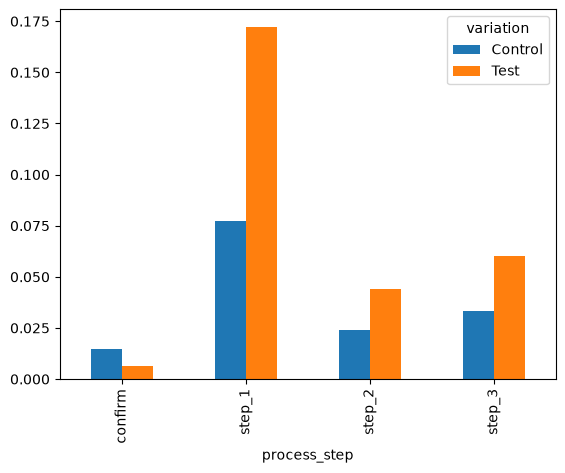

In [19]:
restarts_per_100.plot(kind = "bar")

HYPOTHESIS
H0: p_Test = p_Control -> The percentage of the visits that restart is the same in both groups 
H1: p_Test != p_Control -> the percentage is different
alpha = 0.05

In [25]:
alpha = 0.05
#getting the number of restarted visits, adding all the True values
restarts_count = visits.groupby("variation")["restarted"].sum()
restarts_count



variation
Control    4079
Test       8360
Name: restarted, dtype: int64

In [29]:
# getting the total of the visits (rows) per group 
visits_count = visits.groupby("variation")["restarted"].count()
visits_count

variation
Control    32237
Test       37190
Name: restarted, dtype: int64

In [31]:
# putting the two together
pd.DataFrame({"restarted visits": restarts_count, "total visits": visits_count})

,restarted visits,total visits
variation,,
Control,4079,32237
Test,8360,37190


Z TEST



In [39]:
#Turning the groups restarted column to ceros and ones 
test_restart = visits[visits["variation"] == "Test"]["restarted"].astype(int)
test_restart.mean().round(4)

np.float64(0.2248)

In [40]:
control_restart = visits[visits["variation"] == "Control"]["restarted"].astype(int)
control_restart.mean().round(4)

np.float64(0.1265)

In [37]:
import scipy.stats as st
st.ttest_ind(test_restart, control_restart, equal_var=False, alternative="two-sided")

TtestResult(statistic=np.float64(34.494580655455266), pvalue=np.float64(1.5618181602813312e-258), df=np.float64(68940.656431104))

p value < 0.05
We reject H0, the restart rate is different in Test and Control

chi-square test

In [42]:
# Creating the crosstab for the chi-square test
crosstab_restart = pd.crosstab(visits["variation"], visits["restarted"])
crosstab_restart

restarted,False,True
variation,,
Control,28158,4079
Test,28830,8360


<Axes: xlabel='restarted', ylabel='variation'>

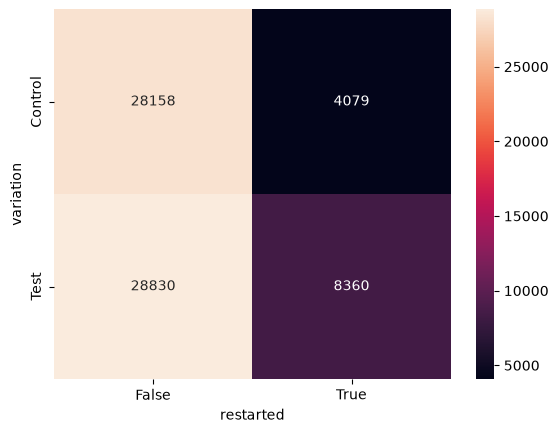

In [51]:
sns.heatmap(crosstab_restart, annot=True, fmt="d")


In [57]:
from scipy.stats import chi2_contingency 
chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(crosstab_restart)
chi2_p_value

np.float64(2.1988309709631828e-248)

Conclusions
- Test restarts more than Control, 77% more
- The difference is not chance, confirmed with chi-square test and Welch's t-test with a p value significantly lower than 0.05 
- Most of the extra restarts come from step_1